## Importando bibliotecas e funções

In [5]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import src.stability as stability

from importlib import reload
reload(stability)

<module 'src.stability' from 'd:\\Projetos Python\\Mestrado\\RBras - Copia\\src\\stability.py'>

In [6]:
from importlib import reload

import src.stability as stability

reload(stability)

from src.stability import (
    load_best_models,
    run_stability_analysis
)

## Definindo os Caminhos

In [29]:
ROOT_DIR = Path.cwd().parent

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

# Diretórios
DATA_DIR = ROOT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
PCA_DIR = PROCESSED_DIR / "pca"
RESULTS_DIR = ROOT_DIR / "results"

RESULTS_DIR.mkdir(exist_ok=True)

## Carregando os Dados

In [15]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np

from src.preprocessing import (
    load_clinical_data,
    map_patient_subtypes
)

from src.stability import (
    load_best_models,
    run_stability_analysis
)

# ------------------------------------------------------------
# 1. Definir diretórios do projeto
# ------------------------------------------------------------

ROOT_DIR = Path.cwd().parent

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

DATA_DIR = ROOT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
PCA_DIR = PROCESSED_DIR / "pca"
RESULTS_DIR = ROOT_DIR / "results"

# ------------------------------------------------------------
# 2. Carregar os conjuntos de dados PCA
# ------------------------------------------------------------

cenarios_mad = {
    "MAD 3.000": "PCA_MAD 3.000.csv",
    "MAD 5.000": "PCA_MAD 5.000.csv",
    "MAD 10.000": "PCA_MAD 10.000.csv",
    "MAD 20.000": "PCA_MAD 20.000.csv"
}

datasets_pca = {}

for nome, arquivo in cenarios_mad.items():

    caminho = PCA_DIR / arquivo

    df = pd.read_csv(caminho, index_col=0)

    datasets_pca[nome] = df

    print(f"{nome}: {df.shape}")

# ------------------------------------------------------------
# 3. Carregar dados clínicos
# ------------------------------------------------------------

PATH_CLINICO = PROCESSED_DIR / "clinical_final.csv"

pacientes, dict_subtipos = load_clinical_data(PATH_CLINICO)

print("\nPacientes carregados:", len(pacientes))
print("Subtipos mapeados:", len(dict_subtipos))

# ------------------------------------------------------------
# 4. Mapear os rótulos PAM50 para cada cenário
# ------------------------------------------------------------

labels_pam50 = {}

for nome, df in datasets_pca.items():

    y = map_patient_subtypes(
        df.index,
        dict_subtipos
    )

    labels_pam50[nome] = y

    print(f"\n{nome}")
    print(y.value_counts())

# ------------------------------------------------------------
# 5. Carregar os melhores modelos do Grid Search
# ------------------------------------------------------------

PATH_BEST_MODELS = (
    RESULTS_DIR / "best_models" / "best_models_params.json"
)

best_models = load_best_models(PATH_BEST_MODELS)

print("\nMelhores modelos carregados:", len(best_models))

# ------------------------------------------------------------
# 6. Conferir alinhamento entre dados e rótulos
# ------------------------------------------------------------

print("\nVERIFICAÇÃO DOS DADOS")

for nome in datasets_pca:

    n_amostras = len(datasets_pca[nome])
    n_rotulos = len(labels_pam50[nome])

    n_desconhecidos = (
        labels_pam50[nome] == "Desconhecido"
    ).sum()

    print(
        f"{nome} | "
        f"Amostras: {n_amostras} | "
        f"Rótulos: {n_rotulos} | "
        f"Desconhecidos: {n_desconhecidos}"
    )

    assert n_amostras == n_rotulos, (
        f"Quantidade de amostras e rótulos diferente em {nome}"
    )

    assert datasets_pca[nome].index.equals(
        labels_pam50[nome].index
    ), f"Ordem das amostras divergente em {nome}"

print("\nImportação e verificação concluídas.")


MAD 3.000: (970, 50)
MAD 5.000: (970, 50)
MAD 10.000: (970, 50)
MAD 20.000: (970, 50)

Pacientes carregados: 970
Subtipos mapeados: 970

MAD 3.000
SUBTYPE
BRCA_LumA      494
BRCA_LumB      193
BRCA_Basal     171
BRCA_Her2       77
BRCA_Normal     35
Name: count, dtype: int64

MAD 5.000
SUBTYPE
BRCA_LumA      494
BRCA_LumB      193
BRCA_Basal     171
BRCA_Her2       77
BRCA_Normal     35
Name: count, dtype: int64

MAD 10.000
SUBTYPE
BRCA_LumA      494
BRCA_LumB      193
BRCA_Basal     171
BRCA_Her2       77
BRCA_Normal     35
Name: count, dtype: int64

MAD 20.000
SUBTYPE
BRCA_LumA      494
BRCA_LumB      193
BRCA_Basal     171
BRCA_Her2       77
BRCA_Normal     35
Name: count, dtype: int64

Melhores modelos carregados: 16

VERIFICAÇÃO DOS DADOS
MAD 3.000 | Amostras: 970 | Rótulos: 970 | Desconhecidos: 0
MAD 5.000 | Amostras: 970 | Rótulos: 970 | Desconhecidos: 0
MAD 10.000 | Amostras: 970 | Rótulos: 970 | Desconhecidos: 0
MAD 20.000 | Amostras: 970 | Rótulos: 970 | Desconhecidos: 0

Imp

## Importando os parâmetros dos Melhores Modelos

In [27]:
from importlib import reload
import src.experiments as experiments
import src.stability as stability

reload(experiments)
reload(stability)

best_models = stability.load_best_models(
    RESULTS_DIR / "best_models" / "best_models_params.json"
)

In [28]:
for model in best_models:

    print(
        model["Cenario"],
        model["Reduction"],
        model["Clustering"]
    )

    print(model["Reduction_params"])
    print(model["Clustering_params"])

    if model["Clustering"] == "HDBSCAN":
        assert isinstance(
            model["Clustering_params"]["min_cluster_size"], int
        )
        assert isinstance(
            model["Clustering_params"]["min_samples"], int
        )

MAD 3.000 UMAP HDBSCAN
{'n_neighbors': 15, 'min_dist': 0.01}
{'min_cluster_size': 15, 'min_samples': 10}
MAD 3.000 UMAP Leiden
{'n_neighbors': 15, 'min_dist': 0.01}
{'n_neighbors': 50, 'resolution': 0.1}
MAD 3.000 PaCMAP HDBSCAN
{'n_neighbors': 50, 'MN_ratio': 0.5, 'FP_ratio': 2.0}
{'min_cluster_size': 50, 'min_samples': 15}
MAD 3.000 PaCMAP Leiden
{'n_neighbors': 50, 'MN_ratio': 0.5, 'FP_ratio': 2.0}
{'n_neighbors': 15, 'resolution': 0.05}
MAD 5.000 PaCMAP HDBSCAN
{'n_neighbors': 50, 'MN_ratio': 0.5, 'FP_ratio': 2.0}
{'min_cluster_size': 50, 'min_samples': 10}
MAD 5.000 PaCMAP Leiden
{'n_neighbors': 50, 'MN_ratio': 0.5, 'FP_ratio': 2.0}
{'n_neighbors': 30, 'resolution': 0.05}
MAD 10.000 PaCMAP HDBSCAN
{'n_neighbors': 50, 'MN_ratio': 0.5, 'FP_ratio': 3.0}
{'min_cluster_size': 15, 'min_samples': 5}
MAD 10.000 PaCMAP Leiden
{'n_neighbors': 50, 'MN_ratio': 0.5, 'FP_ratio': 3.0}
{'n_neighbors': 30, 'resolution': 0.05}
MAD 5.000 UMAP HDBSCAN
{'n_neighbors': 15, 'min_dist': 0.01}
{'min_clust

## Análise das métricas por MAD

In [30]:
resultados_stability = []
resumos_stability = []
labels_stability = {}

for nome, df in datasets_pca.items():

    print(f"\n{'='*50}")
    print(f"Cenário: {nome}")
    print(f"{'='*50}")

    # Selecionar os modelos do cenário atual
    models_scenario = [
        model for model in best_models
        if model["Cenario"] == nome
    ]

    if not models_scenario:
        print("Nenhum modelo encontrado para este cenário.")
        continue

    # Dados e rótulos
    X = df.to_numpy(dtype=float)
    y_true = labels_pam50[nome].to_numpy()

    # Executar estabilidade
    df_runs, df_summary, labels = run_stability_analysis(
        X=X,
        best_models=models_scenario,
        labels_true=y_true,
        n_runs=10,
        base_seed=42,
        n_neighbors_metric=15,
        output_dir=RESULTS_DIR / "stability" / nome,
        verbose=False
    )

    resultados_stability.append(df_runs)
    resumos_stability.append(df_summary)
    labels_stability.update(labels)


# Consolidar resultados
df_stability_runs = pd.concat(
    resultados_stability,
    ignore_index=True
)

df_stability_summary = pd.concat(
    resumos_stability,
    ignore_index=True
)

display(df_stability_summary)


Cenário: MAD 3.000


d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copi


Cenário: MAD 5.000


d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copi


Cenário: MAD 10.000


d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copi


Cenário: MAD 20.000


d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copia\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\Projetos Python\Mestrado\RBras - Copi

,Model_ID,Cenario,Reduction,Clustering,N_Runs,Trustworthiness_media,Trustworthiness_std,Silhouette_media,Silhouette_std,ARI_media,ARI_std,NMI_media,NMI_std,N_Clusters_media,N_Clusters_std,N_Noise_media,N_Noise_std,ARI_estabilidade_media,ARI_estabilidade_std
0,MAD 3.000_PaCMAP_HDBSCAN,MAD 3.000,PaCMAP,HDBSCAN,10,0.903458,0.001574,0.836633,0.001594,0.334482,0.001537,0.483297,0.002735,2.0,0.000000,0.0,0.0,0.994876,0.003458
1,MAD 3.000_PaCMAP_Leiden,MAD 3.000,PaCMAP,Leiden,10,0.903458,0.001574,0.764185,0.153022,0.344153,0.026285,0.487126,0.010739,2.2,0.421637,0.0,0.0,0.774122,0.293461
2,MAD 3.000_UMAP_HDBSCAN,MAD 3.000,UMAP,HDBSCAN,10,0.919470,0.002369,0.819645,0.028828,0.331807,0.001971,0.481315,0.001690,2.0,0.000000,0.0,0.0,0.996419,0.004876
3,MAD 3.000_UMAP_Leiden,MAD 3.000,UMAP,Leiden,10,0.919470,0.002369,0.819645,0.028828,0.331807,0.001971,0.481315,0.001690,2.0,0.000000,0.0,0.0,0.996419,0.004876
4,MAD 5.000_PaCMAP_HDBSCAN,MAD 5.000,PaCMAP,HDBSCAN,10,0.896948,0.001582,0.828025,0.001110,0.337413,0.001282,0.487357,0.001747,2.0,0.000000,0.0,0.0,0.997222,0.002930
5,MAD 5.000_PaCMAP_Leiden,MAD 5.000,PaCMAP,Leiden,10,0.896948,0.001582,0.828025,0.001110,0.337413,0.001282,0.487357,0.001747,2.0,0.000000,0.0,0.0,0.997222,0.002930
6,MAD 5.000_UMAP_HDBSCAN,MAD 5.000,UMAP,HDBSCAN,10,0.917257,0.003256,0.775922,0.022992,0.326258,0.002115,0.475097,0.003568,2.0,0.000000,0.0,0.0,0.996629,0.003732
7,MAD 5.000_UMAP_Leiden,MAD 5.000,UMAP,Leiden,10,0.917257,0.003256,0.775922,0.022992,0.326258,0.002115,0.475097,0.003568,2.0,0.000000,0.0,0.0,0.996629,0.003732
8,MAD 10.000_PaCMAP_HDBSCAN,MAD 10.000,PaCMAP,HDBSCAN,10,0.911576,0.002236,0.817523,0.002256,0.343573,0.001911,0.496250,0.002713,2.0,0.000000,0.0,0.0,0.994486,0.004508
9,MAD 10.000_PaCMAP_Leiden,MAD 10.000,PaCMAP,Leiden,10,0.911576,0.002236,0.817523,0.002256,0.343573,0.001911,0.496250,0.002713,2.0,0.000000,0.0,0.0,0.994486,0.004508


In [31]:
print("Dimensões dos resultados por execução:")
print(df_stability_runs.shape)

print("\nDimensões dos resumos:")
print(df_stability_summary.shape)

print("\nModelos avaliados:")
print(df_stability_summary["Model_ID"].nunique())

display(df_stability_summary)

Dimensões dos resultados por execução:
(160, 12)

Dimensões dos resumos:
(16, 19)

Modelos avaliados:
16


,Model_ID,Cenario,Reduction,Clustering,N_Runs,Trustworthiness_media,Trustworthiness_std,Silhouette_media,Silhouette_std,ARI_media,ARI_std,NMI_media,NMI_std,N_Clusters_media,N_Clusters_std,N_Noise_media,N_Noise_std,ARI_estabilidade_media,ARI_estabilidade_std
0,MAD 3.000_PaCMAP_HDBSCAN,MAD 3.000,PaCMAP,HDBSCAN,10,0.903458,0.001574,0.836633,0.001594,0.334482,0.001537,0.483297,0.002735,2.0,0.000000,0.0,0.0,0.994876,0.003458
1,MAD 3.000_PaCMAP_Leiden,MAD 3.000,PaCMAP,Leiden,10,0.903458,0.001574,0.764185,0.153022,0.344153,0.026285,0.487126,0.010739,2.2,0.421637,0.0,0.0,0.774122,0.293461
2,MAD 3.000_UMAP_HDBSCAN,MAD 3.000,UMAP,HDBSCAN,10,0.919470,0.002369,0.819645,0.028828,0.331807,0.001971,0.481315,0.001690,2.0,0.000000,0.0,0.0,0.996419,0.004876
3,MAD 3.000_UMAP_Leiden,MAD 3.000,UMAP,Leiden,10,0.919470,0.002369,0.819645,0.028828,0.331807,0.001971,0.481315,0.001690,2.0,0.000000,0.0,0.0,0.996419,0.004876
4,MAD 5.000_PaCMAP_HDBSCAN,MAD 5.000,PaCMAP,HDBSCAN,10,0.896948,0.001582,0.828025,0.001110,0.337413,0.001282,0.487357,0.001747,2.0,0.000000,0.0,0.0,0.997222,0.002930
5,MAD 5.000_PaCMAP_Leiden,MAD 5.000,PaCMAP,Leiden,10,0.896948,0.001582,0.828025,0.001110,0.337413,0.001282,0.487357,0.001747,2.0,0.000000,0.0,0.0,0.997222,0.002930
6,MAD 5.000_UMAP_HDBSCAN,MAD 5.000,UMAP,HDBSCAN,10,0.917257,0.003256,0.775922,0.022992,0.326258,0.002115,0.475097,0.003568,2.0,0.000000,0.0,0.0,0.996629,0.003732
7,MAD 5.000_UMAP_Leiden,MAD 5.000,UMAP,Leiden,10,0.917257,0.003256,0.775922,0.022992,0.326258,0.002115,0.475097,0.003568,2.0,0.000000,0.0,0.0,0.996629,0.003732
8,MAD 10.000_PaCMAP_HDBSCAN,MAD 10.000,PaCMAP,HDBSCAN,10,0.911576,0.002236,0.817523,0.002256,0.343573,0.001911,0.496250,0.002713,2.0,0.000000,0.0,0.0,0.994486,0.004508
9,MAD 10.000_PaCMAP_Leiden,MAD 10.000,PaCMAP,Leiden,10,0.911576,0.002236,0.817523,0.002256,0.343573,0.001911,0.496250,0.002713,2.0,0.000000,0.0,0.0,0.994486,0.004508


## Ordenação dos modelos por ARI

In [32]:
df_stability_summary_ordenado = (
    df_stability_summary
    .sort_values(
        by="ARI_estabilidade_media",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    df_stability_summary_ordenado[
        [
            "Model_ID",
            "ARI_estabilidade_media",
            "ARI_estabilidade_std",
            "Silhouette_media",
            "Trustworthiness_media",
            "ARI_media",
            "N_Clusters_media",
            "N_Noise_media"
        ]
    ]
)

,Model_ID,ARI_estabilidade_media,ARI_estabilidade_std,Silhouette_media,Trustworthiness_media,ARI_media,N_Clusters_media,N_Noise_media
0,MAD 10.000_UMAP_HDBSCAN,0.998200,0.002451,0.730093,0.914692,0.326763,2.0,0.0
1,MAD 10.000_UMAP_Leiden,0.998200,0.002451,0.730093,0.914692,0.326763,2.0,0.0
2,MAD 5.000_PaCMAP_Leiden,0.997222,0.002930,0.828025,0.896948,0.337413,2.0,0.0
3,MAD 5.000_PaCMAP_HDBSCAN,0.997222,0.002930,0.828025,0.896948,0.337413,2.0,0.0
4,MAD 5.000_UMAP_Leiden,0.996629,0.003732,0.775922,0.917257,0.326258,2.0,0.0
5,MAD 5.000_UMAP_HDBSCAN,0.996629,0.003732,0.775922,0.917257,0.326258,2.0,0.0
6,MAD 3.000_UMAP_HDBSCAN,0.996419,0.004876,0.819645,0.919470,0.331807,2.0,0.0
7,MAD 3.000_UMAP_Leiden,0.996419,0.004876,0.819645,0.919470,0.331807,2.0,0.0
8,MAD 3.000_PaCMAP_HDBSCAN,0.994876,0.003458,0.836633,0.903458,0.334482,2.0,0.0
9,MAD 10.000_PaCMAP_Leiden,0.994486,0.004508,0.817523,0.911576,0.343573,2.0,0.0


## Comparação da estabilidade das métricas por MAD

In [33]:
comparacao_mad = (
    df_stability_summary
    .groupby("Cenario")
    .agg(
        Estabilidade_media=(
            "ARI_estabilidade_media",
            "mean"
        ),
        Estabilidade_dp=(
            "ARI_estabilidade_media",
            "std"
        ),
        Silhouette_media=(
            "Silhouette_media",
            "mean"
        ),
        ARI_PAM50_media=(
            "ARI_media",
            "mean"
        )
    )
    .reset_index()
)

display(comparacao_mad)

,Cenario,Estabilidade_media,Estabilidade_dp,Silhouette_media,ARI_PAM50_media
0,MAD 10.000,0.996343,0.002144,0.773808,0.335168
1,MAD 20.000,0.901435,0.090149,0.656029,0.323547
2,MAD 3.000,0.940459,0.110894,0.810027,0.335562
3,MAD 5.000,0.996926,0.000342,0.801973,0.331835


## Plot das estabilidades

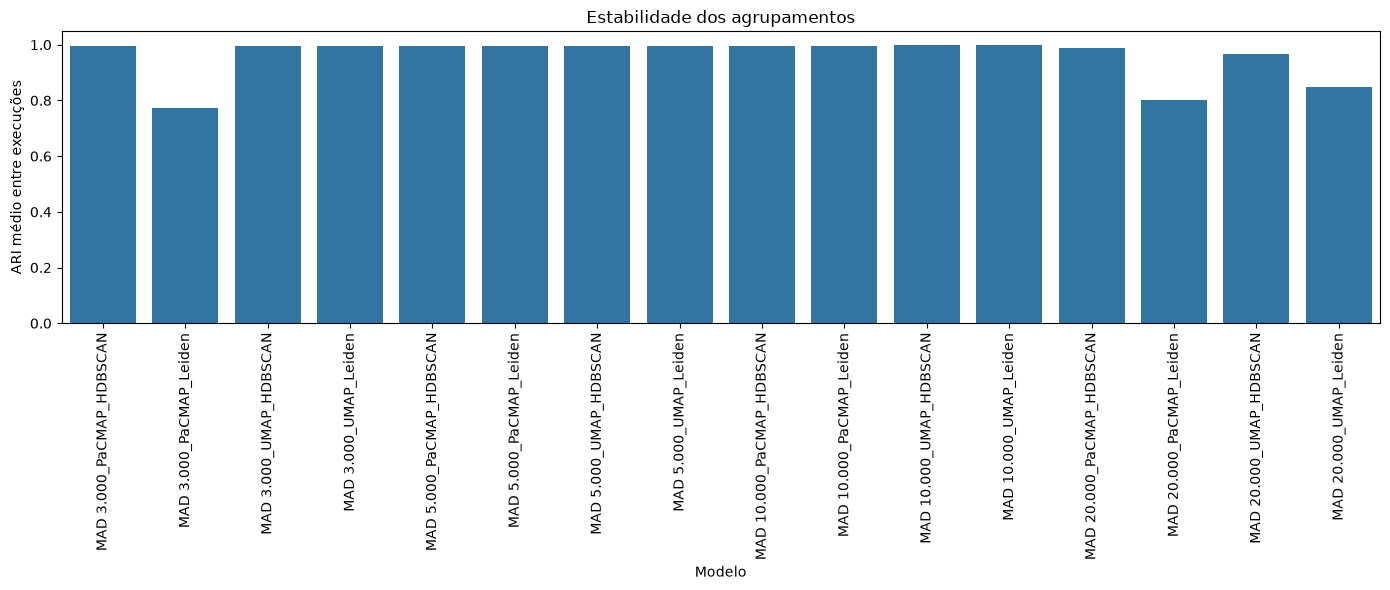

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.barplot(
    data=df_stability_summary,
    x="Model_ID",
    y="ARI_estabilidade_media"
)

plt.xticks(rotation=90)
plt.xlabel("Modelo")
plt.ylabel("ARI médio entre execuções")
plt.title("Estabilidade dos agrupamentos")

plt.tight_layout()
plt.show()

## Salvar os resultados

In [35]:
PATH_RESULTADOS = RESULTS_DIR / "stability"

PATH_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

df_stability_runs.to_csv(
    PATH_RESULTADOS / "stability_runs_consolidado.csv",
    index=False
)

df_stability_summary.to_csv(
    PATH_RESULTADOS / "stability_summary_consolidado.csv",
    index=False
)

comparacao_mad.to_csv(
    PATH_RESULTADOS / "comparacao_mad.csv",
    index=False
)